<a href="https://colab.research.google.com/github/TharunPatel20/UST-GenAIEngineer-cohort-4/blob/main/Assignment1_Diabetes_Prediction_using_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [179]:
import pandas as pd
data = pd.read_csv("/content/sample_data/diabetes.csv")
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [180]:
print(data.shape) #to check rows and columns in

(768, 9)


In [181]:
print(data.columns.tolist())
print(data.dtypes)
print("Null values per column:\n", data.isna().sum())

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object
Null values per column:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [182]:
cols_with_zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((data[cols_with_zero_as_missing] == 0).sum())


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [183]:
data.describe() # check the dataset description


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [184]:
X = data.drop(columns="Outcome")
y = data["Outcome"]
print(X.shape, y.shape)
print(y.value_counts(normalize=True).round(3))

(768, 8) (768,)
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


In [185]:
from sklearn.model_selection import train_test_split
# split test-data 30%, train-data 70%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

Train: (537, 8) Test: (231, 8)
Outcome
0    0.652
1    0.348
Name: proportion, dtype: float64
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


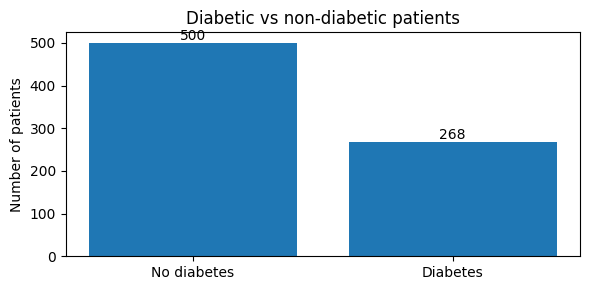

In [186]:
import matplotlib.pyplot as plt

counts = y.value_counts().sort_index()

plt.figure(figsize=(6, 3))
plt.bar(["No diabetes", "Diabetes"], counts.values)
for i, v in enumerate(counts.values):
    plt.text(i, v + 8, str(v), ha="center")
plt.title("Diabetic vs non-diabetic patients")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()

In [187]:
import numpy as np

X_train = X_train.copy()
X_test = X_test.copy()

for col in cols_with_zero_as_missing:
    X_train[col] = X_train[col].replace(0, np.nan)
    X_test[col] = X_test[col].replace(0, np.nan)
    median = X_train[col].median()          # learned from train only
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

print((X_train[cols_with_zero_as_missing] == 0).sum())
print((X_test[cols_with_zero_as_missing] == 0).sum())

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [188]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean and std from train only
X_test_scaled = scaler.transform(X_test)         # apply the same mean and std to test

print("Train scaled mean (approx):", X_train_scaled.mean(axis=0).round(2))
print("Train scaled std  (approx):", X_train_scaled.std(axis=0).round(2))

Train scaled mean (approx): [ 0.  0. -0.  0.  0. -0.  0. -0.]
Train scaled std  (approx): [1. 1. 1. 1. 1. 1. 1. 1.]


In [189]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1500)

## Why Logistic Regression?

The target, Outcome, is binary: 1 means diabetes and 0 means no diabetes. Logistic Regression is built for this kind of yes/no problem. It combines the features into a weighted score and passes that score through a sigmoid function, which turns it into a probability between 0 and 1. A patient is predicted as diabetic when that probability crosses a threshold, usually 0.5.

It's a suitable first model here for three reasons:

1. It handles binary classification directly, without any extra setup.
2. Its coefficients show how much each feature pushes the prediction up or down, which helps with the business insights in Part 4.
3. It's simple, so it's less likely to overfit a dataset of 768 patients than a more complex model would be.

Its limitation is that it assumes a roughly linear relationship between the features and the log-odds of the outcome. We'll check the results to see whether that assumption is a problem.

In [190]:
model.fit(X_train_scaled, y_train)
print("Model trained. Coefficients:", model.coef_.shape)

Model trained. Coefficients: (1, 8)


In [191]:
y_train_pred = model.predict(X_train_scaled)

print("First 10 predictions:", y_train_pred[:10])
print("First 10 actual:     ", y_train.values[:10])
print("Predicted class counts:", pd.Series(y_train_pred).value_counts().to_dict())

First 10 predictions: [1 0 0 0 0 1 1 0 0 0]
First 10 actual:      [1 0 0 0 0 1 0 0 0 0]
Predicted class counts: {0: 393, 1: 144}


In [192]:
from sklearn.metrics import accuracy_score

train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training accuracy: {train_acc}")

Training accuracy: 0.7858472998137802


In [193]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

X_test_scaled = scaler.transform(X_test)
y_test_pred = model.predict(X_test_scaled)

print("Training accuracy  :",train_acc)
print("Test accuracy      :",accuracy_score(y_test, y_test_pred))
print("Gap                :",train_acc - accuracy_score(y_test, y_test_pred))
print("Precision          :",precision_score(y_test, y_test_pred))
print("Recall             :",recall_score(y_test, y_test_pred))
print("F1-score           :",f1_score(y_test, y_test_pred))
print("\nConfusion matrix (rows = actual, cols = predicted):")
print(confusion_matrix(y_test, y_test_pred))

Training accuracy  : 0.7858472998137802
Test accuracy      : 0.7445887445887446
Gap                : 0.04125855522503563
Precision          : 0.671875
Recall             : 0.5308641975308642
F1-score           : 0.593103448275862

Confusion matrix (rows = actual, cols = predicted):
[[129  21]
 [ 38  43]]
